# Getting Started with pandas {.unnumbered}

Almost every chapter of this script works with tables: measurements with time stamps, test results per part, sensor values per run. In Python, such tables are handled with **pandas**. This lesson introduces pandas for everyone who has not used it before – and shows the typical *style* of pandas code, which differs from the NumPy and Matplotlib code you may know. It takes about 90 minutes; work through it before Chapter 1, run every cell yourself and change things to see what happens.

**Prerequisites.** Basic Python (variables, lists, dictionaries, functions, loops) and a first contact with NumPy and Matplotlib.

**Learning goals.** After this lesson you can

- explain what a Series and a DataFrame are and how they extend NumPy arrays,
- read a text file into a DataFrame and get a first overview,
- select rows and columns by name, by condition and by position,
- compute new columns without loops and summarise columns, also per group,
- work with time stamps and plot directly from pandas,
- read and write code in the typical pandas style.

**Dataset.** A small, invented production log: shafts with a nominal diameter of 25 mm are turned on three machines, and one part per hour is measured; parts that deviate by more than 12 µm are scrapped. The data are created in the lesson itself, so no download is needed.

## Why pandas? {.unnumbered}

A NumPy array is fast, but it usually holds only numbers, all of the same type, addressed by position: `a[3]` is "the fourth value". Real engineering tables are different:

- columns have **names** and **different types** – a machine ID (text), a diameter (number), a time stamp, a pass/fail result;
- rows often have a meaningful **label**, e.g. a time stamp or a part number;
- values are **missing**.

pandas adds exactly this to NumPy: names, labels, mixed types and missing values. Underneath, the numbers are still stored in NumPy arrays, so the speed of vectorised operations remains. First the usual setup:

In [1]:
#| code-fold: false
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")             # common style for all plots, as in every chapter
pd.set_option("display.precision", 3)        # show 3 decimals in tables

## Series and DataFrame {.unnumbered}

A **Series** is a single column: values plus labels, the **index**.

In [2]:
#| code-fold: false
temps = pd.Series([21.5, 22.0, 23.1],                    # the values
                  index=["M1", "M2", "M3"],              # the labels (index)
                  name="spindle_temp_C")                 # an optional name
temps

M1    21.5
M2    22.0
M3    23.1
Name: spindle_temp_C, dtype: float64

Access works by label, and arithmetic works on all values at once – as in NumPy. The labels are kept:

In [3]:
#| code-fold: false
print(temps["M2"])                 # one value, by its label
temps * 1.8 + 32                   # °C -> °F for all values; no loop needed

22.0


M1    70.70
M2    71.60
M3    73.58
Name: spindle_temp_C, dtype: float64

A **DataFrame** is a table: several Series that share one index. The easiest way to create one is a dictionary whose keys become the column names:

In [4]:
#| code-fold: false
parts = pd.DataFrame({
    "machine":     ["M1", "M2", "M3"],
    "diameter_mm": [25.003, 24.998, 25.012],
    "ok":          [True, True, False],
})
parts

,machine,diameter_mm,ok
0,M1,25.003,True
1,M2,24.998,True
2,M3,25.012,False


The index on the left (0, 1, 2) was created automatically. Each column has its own data type:

In [5]:
#| code-fold: false
parts.dtypes          # str = text (object in pandas < 3.0), float64 = decimal number, bool = True/False

machine            str
diameter_mm    float64
ok                bool
dtype: object

## Reading a file and a first look {.unnumbered}

In practice, tables come from files. The folded cell below creates our example file `data/shafts.csv` – in a real project, you would receive such a file from a measuring machine or a database export. Like many files from German software, it uses a semicolon as separator and a decimal comma.

In [6]:
#| code-fold: true
# Creates the example file data/shafts.csv (4 days, 6:00-20:00, one measured part per hour).
from pathlib import Path
rng = np.random.default_rng(9)
days = pd.date_range("2025-03-03", periods=4, freq="D")                 # Monday to Thursday
time = pd.DatetimeIndex([d + pd.Timedelta(hours=h) for d in days for h in range(6, 21)])  # 6:00-20:00
n = len(time)                                                           # 60 parts
machine = np.tile(["M1", "M2", "M3"], n // 3)
offset = np.where(machine == "M3", 0.008, 0.0)                         # M3 is set too large
diameter = 25.0 + offset + rng.normal(0, 0.004, n)
warm_up = 1 - np.exp(-(time.hour.to_numpy() - 6) / 3)                  # spindle warms up after 6:00
spindle = 20 + 8 * warm_up + rng.normal(0, 0.4, n)
log = pd.DataFrame({
    "time": time.strftime("%d.%m.%Y %H:%M"),                           # German date format
    "machine": machine,
    "diameter_mm": diameter.round(4),
    "spindle_temp_C": spindle.round(1),
})
log["result"] = np.where((log["diameter_mm"] - 25).abs() > 0.012, "scrap", "OK")   # tolerance ±12 µm
log.loc[[17, 40], "spindle_temp_C"] = np.nan                            # two missing readings
Path("data").mkdir(exist_ok=True)
log.to_csv("data/shafts.csv", sep=";", decimal=",", index=False)

`pd.read_csv` reads the file. Separator and decimal mark are stated explicitly:

In [7]:
#| code-fold: false
shafts = pd.read_csv("data/shafts.csv", sep=";", decimal=",")
shafts.head()            # the first five rows

,time,machine,diameter_mm,spindle_temp_C,result
0,03.03.2025 06:00,M1,24.997,20.1,OK
1,03.03.2025 07:00,M2,25.001,22.4,OK
2,03.03.2025 08:00,M3,25.001,23.3,OK
3,03.03.2025 09:00,M1,25.003,26.0,OK
4,03.03.2025 10:00,M2,25.005,26.0,OK


Four commands give a first overview of every new table:

In [8]:
#| code-fold: false
print(shafts.shape)      # (rows, columns) – an attribute, therefore without brackets
shafts.info()            # column names, data types, number of non-missing values

(60, 5)
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   time            60 non-null     str    
 1   machine         60 non-null     str    
 2   diameter_mm     60 non-null     float64
 3   spindle_temp_C  58 non-null     float64
 4   result          60 non-null     str    
dtypes: float64(2), str(3)
memory usage: 3.7 KB


In [9]:
#| code-fold: false
shafts.describe()        # summary statistics of all numeric columns

,diameter_mm,spindle_temp_C
count,60.000,58.000
mean,25.002,26.221
std,0.006,2.286
min,24.992,19.900
25%,24.998,26.000
50%,25.001,27.100
75%,25.006,27.700
max,25.017,28.500


In [10]:
#| code-fold: false
shafts["result"].value_counts()      # frequencies of a text column

result
OK       55
scrap     5
Name: count, dtype: int64

`info()` shows that `spindle_temp_C` has 58 non-missing values in 60 rows: two readings are missing. `describe()` ignores them automatically.

## Selecting rows and columns {.unnumbered}

Columns are selected by name. One name gives a Series, a *list* of names gives a DataFrame – hence the double brackets:

In [11]:
#| code-fold: false
d = shafts["diameter_mm"]                         # one column -> Series
shafts[["machine", "diameter_mm"]].head(3)        # list of columns -> DataFrame

,machine,diameter_mm
0,M1,24.997
1,M2,25.001
2,M3,25.001


Rows are selected with a **mask**: a comparison gives one truth value per row, and `df[mask]` keeps the rows where it is `True`.

In [12]:
#| code-fold: false
m3 = shafts["machine"] == "M3"                     # True for every part of machine M3
shafts[m3].head(3)

,time,machine,diameter_mm,spindle_temp_C,result
2,03.03.2025 08:00,M3,25.001,23.3,OK
5,03.03.2025 11:00,M3,25.006,26.3,OK
8,03.03.2025 14:00,M3,25.006,27.5,OK


Several conditions are combined with `&` (and), `|` (or) and `~` (not), each condition in brackets – Python's `and`/`or` do not work on columns:

In [13]:
#| code-fold: false
shafts[(shafts["machine"] == "M3") & (shafts["result"] == "scrap")]

,time,machine,diameter_mm,spindle_temp_C,result
11,03.03.2025 17:00,M3,25.014,28.0,scrap
17,04.03.2025 08:00,M3,25.014,NaN,scrap
23,04.03.2025 14:00,M3,25.017,27.6,scrap
41,05.03.2025 17:00,M3,25.012,27.9,scrap
47,06.03.2025 08:00,M3,25.015,24.0,scrap


For rows *and* columns at once, use `loc` (by label or mask) or `iloc` (by position, counting from 0):

In [14]:
#| code-fold: false
print(shafts.loc[m3, "diameter_mm"].mean().round(4))   # rows: mask, column: by name
shafts.iloc[:2, :3]                              # first two rows, first three columns

25.0085


,time,machine,diameter_mm
0,03.03.2025 06:00,M1,24.997
1,03.03.2025 07:00,M2,25.001


## Computing with columns {.unnumbered}

New columns are computed from existing ones – for all rows at once, without a loop:

In [15]:
#| code-fold: false
shafts["dev_um"] = (shafts["diameter_mm"] - 25.0) * 1000      # deviation from nominal in µm
shafts[["diameter_mm", "dev_um"]].head(3)

,diameter_mm,dev_um
0,24.997,-3.2
1,25.001,1.0
2,25.001,1.4


For comparison, the loop version that you would write in plain Python – it gives the same result but is longer and, for large tables, much slower:

```python
dev = []
for value in shafts["diameter_mm"]:
    dev.append((value - 25.0) * 1000)
shafts["dev_um"] = dev
```

Summaries are **methods** of the column: `s.mean()`, `s.median()`, `s.std()`, `s.abs()`, `s.max()`. They skip missing values automatically:

In [16]:
#| code-fold: false
t = shafts["spindle_temp_C"]
print("missing values:", t.isna().sum())          # isna(): True where a value is missing
print("mean:", t.mean().round(1))                 # computed from the values present
print("mean absolute deviation (µm):", shafts["dev_um"].abs().mean().round(1))

missing values: 2
mean: 26.2
mean absolute deviation (µm): 4.7


The last line shows the typical pandas style: `shafts["dev_um"].abs().mean()` reads from left to right – take the deviation, its absolute value, the mean. NumPy writes the same nested from the inside out, `np.mean(np.abs(...))`. With pandas data, prefer the methods: they skip missing values, NumPy functions often do not (see the Python reference in the appendix).

## Summaries per group {.unnumbered}

"Which machine is best?" is a question about groups. `groupby` splits the table by the values of a column, summarises each part and puts the results together:

In [17]:
#| code-fold: false
shafts.groupby("machine")["dev_um"].agg(["mean", "std", "count"])

,mean,std,count
machine,,,
M1,-0.950,2.299,20
M2,-0.670,4.434,20
M3,8.515,4.733,20


Machine M3 deviates by about +8 µm on average: it is set too large. The scrap rate per machine uses a useful trick – `True` counts as 1, so the mean of a truth value is a share:

In [18]:
#| code-fold: false
shafts["scrap"] = shafts["result"] == "scrap"         # True / False per part
shafts.groupby("machine")["scrap"].mean()             # share of scrap per machine

machine
M1    0.00
M2    0.00
M3    0.25
Name: scrap, dtype: float64

## Time stamps {.unnumbered}

The column `time` is still text. `pd.to_datetime` turns it into real time stamps; the format codes (`%d` day, `%m` month, `%Y` year, `%H` hour, `%M` minute) describe the text exactly:

In [19]:
#| code-fold: false
shafts["time"] = pd.to_datetime(shafts["time"], format="%d.%m.%Y %H:%M")
shafts = shafts.set_index("time")                     # the time becomes the row index
shafts.head(3)

,machine,diameter_mm,spindle_temp_C,result,dev_um,scrap
time,,,,,,
2025-03-03 06:00:00,M1,24.997,20.1,OK,-3.2,False
2025-03-03 07:00:00,M2,25.001,22.4,OK,1.0,False
2025-03-03 08:00:00,M3,25.001,23.3,OK,1.4,False


With a time index, pandas offers time-specific operations, e.g. the hour of each row or a daily mean:

In [20]:
#| code-fold: false
print(shafts.index.hour[:5])                          # hour of the day of the first five rows
shafts["spindle_temp_C"].resample("D").mean()         # one mean per day

Index([6, 7, 8, 9, 10], dtype='int32', name='time')


time
2025-03-03    26.073
2025-03-04    26.371
2025-03-05    26.236
2025-03-06    26.213
Freq: D, Name: spindle_temp_C, dtype: float64

## Plotting from pandas {.unnumbered}

Series and DataFrames have a `plot` method. It calls Matplotlib, takes the x-axis from the index and returns the familiar Matplotlib axes `ax`, so you can continue as usual:

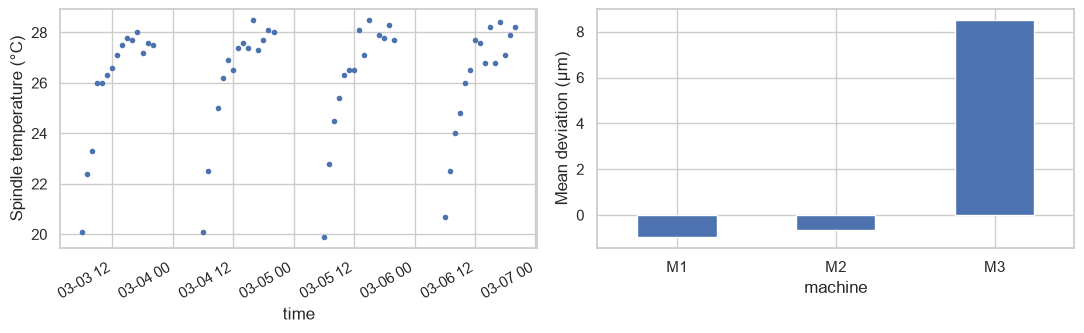

In [21]:
#| code-fold: false
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
shafts["spindle_temp_C"].plot(ax=axes[0], marker=".", linestyle="none")  # time series as points
axes[0].set(ylabel="Spindle temperature (°C)")
shafts.groupby("machine")["dev_um"].mean().plot.bar(ax=axes[1], rot=0)  # bar chart of a summary
axes[1].set(ylabel="Mean deviation (µm)")
plt.tight_layout(); plt.show()

Every morning the spindle starts cold and warms up to about 28 °C (there is no production at night); machine M3 stands out in the bar chart. Two lines of pandas replaced the data handling that Matplotlib alone would need.

## The pandas style in a nutshell {.unnumbered}

| Principle | Example |
| --- | --- |
| Columns by name, not by position | `df["diameter_mm"]` instead of `a[:, 2]` |
| Whole columns at once, no loops | `df["dev_um"] = (df["diameter_mm"] - 25) * 1000` |
| Rows by condition | `df[df["machine"] == "M3"]` |
| Methods, read from left to right | `df["dev_um"].abs().mean()` |
| Missing values are skipped | `s.mean()` uses only the values present |
| Split – apply – combine | `df.groupby("machine")["dev_um"].mean()` |
| Methods return new objects | `df.sort_values("dev_um")` leaves `df` unchanged |

The last principle makes **method chaining** possible: `shafts.groupby("machine")["dev_um"].mean().plot.bar()` is one expression of four steps. The Python quick reference in the appendix collects all functions used in this script – including the pandas functions of this lesson – and explains the design behind chaining.

::: {.callout-important}
## Key takeaways
- A **Series** is a column with labels (index); a **DataFrame** is a table of Series that share one index.
- Read files with `pd.read_csv`, stating separator, decimal mark and missing value codes explicitly; get an overview with `shape`, `info()`, `describe()`, `value_counts()`.
- Select columns by name, rows by masks (`&`, `|`, `~`), both together with `loc` (labels) or `iloc` (positions).
- Compute with whole columns instead of loops; summarise with methods, which skip missing values; use `groupby` for summaries per group.
- With time stamps as index, `resample` and `index.hour` work on the time axis; `.plot()` draws directly from a table.
:::

## Exercises {.unnumbered}

<div class="exercises">

1. How many parts were measured on each machine, and how many of them are scrap? Use `value_counts` or `groupby`.
2. Select all parts with a diameter above 25.010 mm. On which machines were they made?
3. Compute the share of parts per machine whose deviation is within ±10 µm.
4. Compute the mean spindle temperature for each hour of the day and plot it as a line. When is the spindle warm?
5. Rewrite the following loop in pandas style with one line:
   ```python
   count = 0
   for value in shafts["spindle_temp_C"]:
       if value > 27:
           count += 1
   ```
   Does your line give the same result? (Hint: what happens to the two missing values?)

</div>

### Solutions {.unnumbered}

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [22]:
#| code-fold: false
print(shafts["machine"].value_counts())               # parts per machine
shafts.groupby("machine")["scrap"].sum()              # scrap per machine: True counts as 1

machine
M1    20
M2    20
M3    20
Name: count, dtype: int64


machine
M1    0
M2    0
M3    5
Name: scrap, dtype: int64

Each machine made 20 parts. Scrap occurs only on M3, the machine with the offset.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [23]:
#| code-fold: false
large = shafts[shafts["diameter_mm"] > 25.010]        # mask: True for large diameters
large["machine"].value_counts()

machine
M3    9
M2    1
Name: count, dtype: int64

Nearly all large diameters come from M3 – the same offset seen in the group summary.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [24]:
#| code-fold: false
within = shafts["dev_um"].abs() <= 10                 # True if |deviation| <= 10 µm
within.groupby(shafts["machine"]).mean()              # share per machine

machine
M1    1.00
M2    0.95
M3    0.55
Name: dev_um, dtype: float64

The mean of a truth value is a share. `groupby` also accepts a separate column as key, here the machine of each row.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

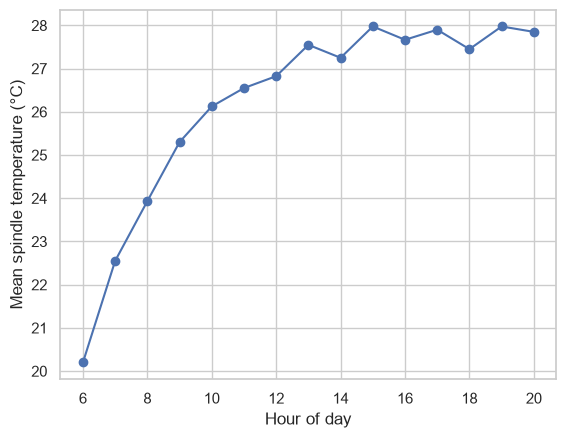

In [25]:
#| code-fold: false
by_hour = shafts.groupby(shafts.index.hour)["spindle_temp_C"].mean()
ax = by_hour.plot(marker="o")
ax.set(xlabel="Hour of day", ylabel="Mean spindle temperature (°C)")
plt.show()

The spindle starts cold at 6:00, warms up over the first hours of the shift and reaches about 28 °C in the early afternoon. Measurements taken early in the morning were made on a cold machine – a possible influence on the diameter worth checking.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

In [26]:
#| code-fold: false
print((shafts["spindle_temp_C"] > 27).sum())          # comparison gives True/False; sum counts True

30


Both versions give the same count: a missing value (`NaN`) compared with 27 gives `False` – in the loop as well as in pandas – so the two missing readings are not counted. The pandas line is shorter, faster and reads like the question: "How many temperatures are above 27 °C?"
:::